# **Task 1**: Verify your Google Cloud environment setup, including capturing proof of your active cloud notebook instance or billing credit balance.


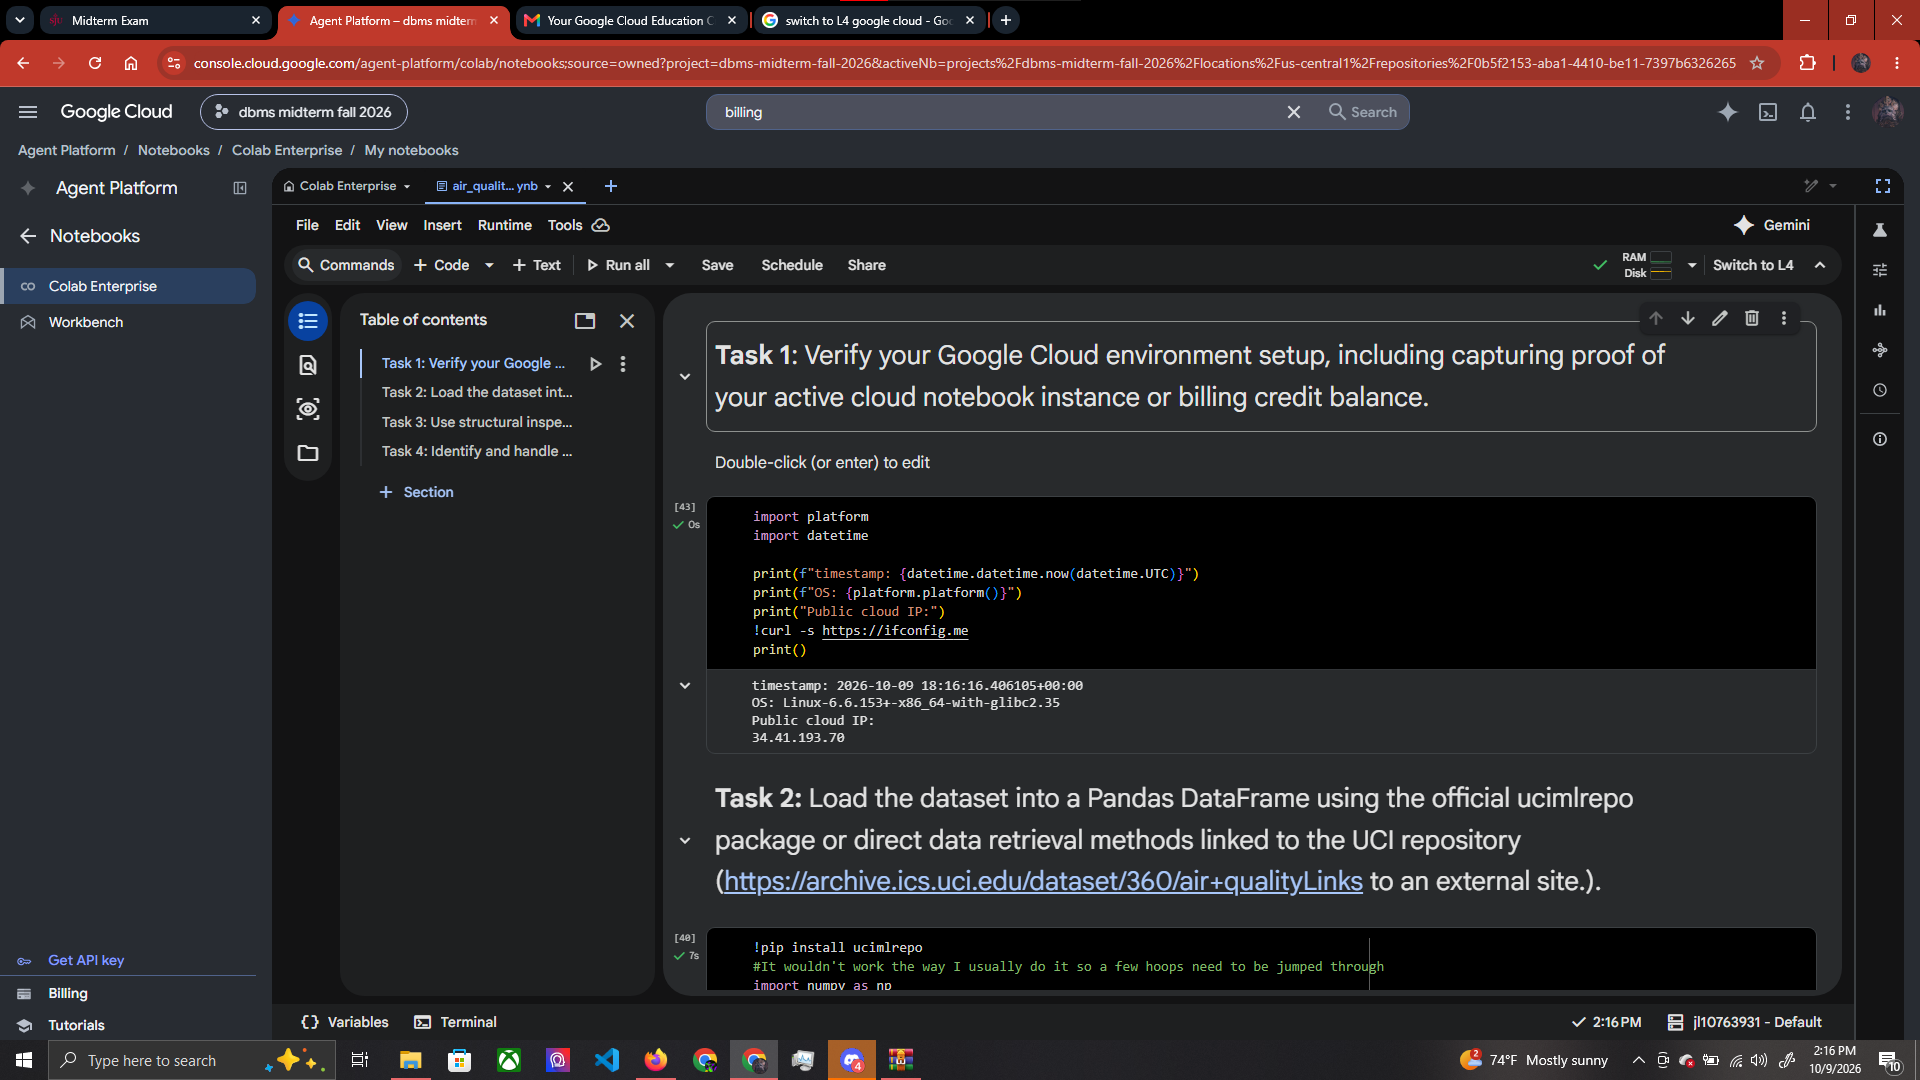

Additional Proof that the billing account connected to this space is indeed the one from the credits given
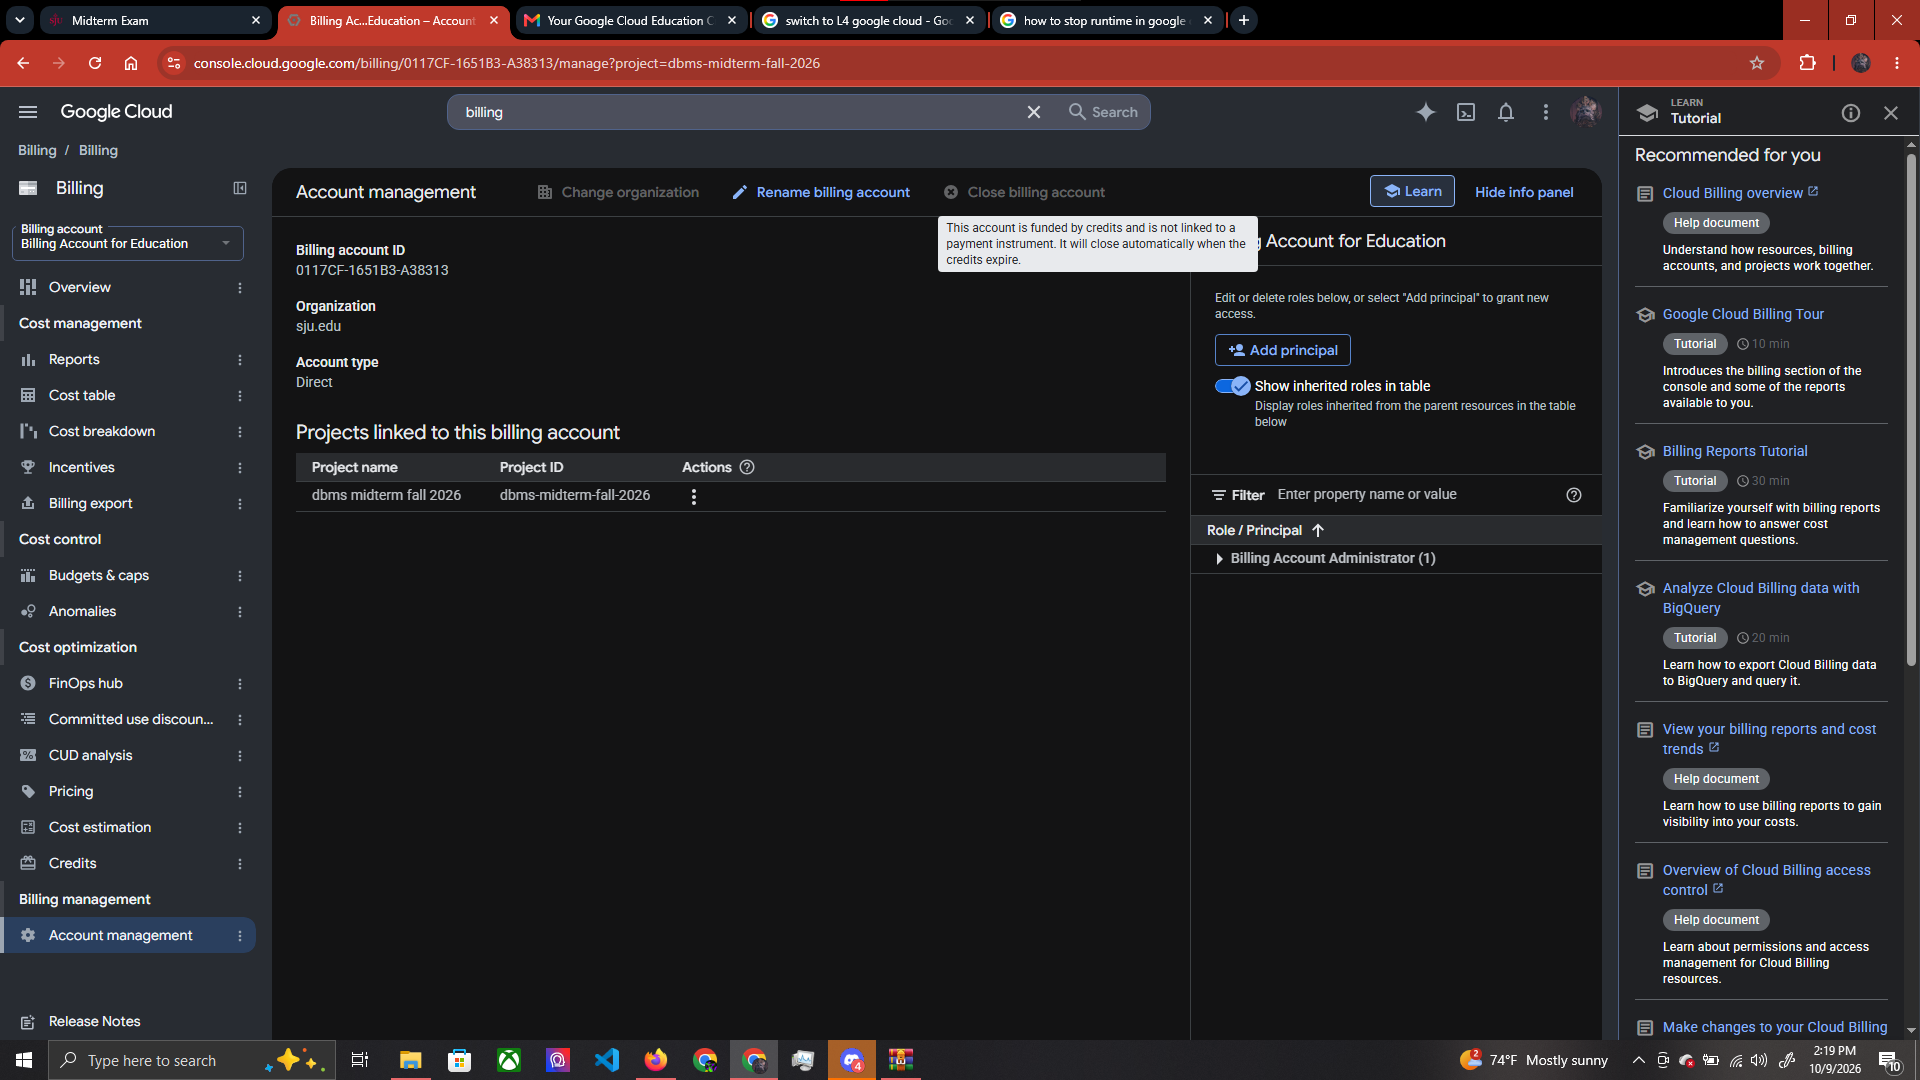

In [29]:
import platform
import datetime

print(f"timestamp: {datetime.datetime.now(datetime.UTC)}")
print(f"OS: {platform.platform()}")
print("Public cloud IP:")
!curl -s https://ifconfig.me
print()

timestamp: 2026-10-09 23:41:39.553916+00:00
OS: Linux-6.6.153+-x86_64-with-glibc2.35
Public cloud IP:
35.188.106.192


# **Task 2:** Load the dataset into a Pandas DataFrame using the official ucimlrepo package or direct data retrieval methods linked to the UCI repository (https://archive.ics.uci.edu/dataset/360/air+qualityLinks to an external site.).

In [30]:
!pip install ucimlrepo
#It wouldn't work the way I usually do it so a few hoops need to be jumped through
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
air_quality = fetch_ucirepo(id=360)
X = air_quality.data.features
y = air_quality.data.targets
df = pd.concat([X, y], axis=1)

# **Task 3**: Use structural inspection methods (head(), info(), describe()) to analyze the dataset structure and examine feature distributions across sensor and meteorological variables.

In [31]:
print("Data Head")
display(df.head())
print("--------------")
print("Data Info")
df.info()
print("--------------")
print("Data Description")
display(df.describe())

Data Head


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


--------------
Data Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB
--------------
Data Description


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


# **Task 4:** Identify and handle implicit missing data values (such as the standard -200 sentinel values present in the air quality dataset) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.

In [32]:
from sklearn.impute import SimpleImputer

true_df = df.replace(-200, np.nan)
print('Before:')
display(true_df.isna().sum())
print('----------')
imp = SimpleImputer(missing_values=np.nan, strategy='median')
false_columns = ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
true_df[false_columns] = imp.fit_transform(true_df[false_columns])
print("After")
display(true_df.isna().sum())

Before:


,0
Date,0
Time,0
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


----------
After


,0
Date,0
Time,0
CO(GT),0
PT08.S1(CO),0
NMHC(GT),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0


# **Task 5:** Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and necessary encoding to categorical/temporal features.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector

num_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
pipeline = ColumnTransformer(transformers=[
    ("num", num_trans, make_column_selector(dtype_include=np.number)),
    ("cat", cat_trans, make_column_selector(dtype_include=["object", "category", "string", "bool"])),
])
df_test = pipeline.fit_transform(true_df)
df_test = pd.DataFrame.sparse.from_spmatrix(
    df_test,
    index=true_df.index,
    columns=pipeline.get_feature_names_out()
)
print(df_test)

      num__CO(GT)  num__PT08.S1(CO)  num__NMHC(GT)  num__C6H6(GT)  \
0        0.386029          1.228781      -0.100241       0.258577   
1       -0.067502          0.909382      -0.666943      -0.083356   
2        0.083675          1.426057      -1.024861      -0.138065   
3        0.083675          1.303934      -1.144167      -0.110711   
4       -0.369856          0.815441       -1.57665      -0.479998   
...           ...               ...            ...            ...   
9352     0.763971          1.012717      -0.100241       0.477414   
9353     0.234852          0.303464      -0.100241        0.19019   
9354     0.234852          0.204826      -0.100241       0.326963   
9355     0.008086         -0.448062      -0.100241      -0.069679   
9356     0.083675         -0.128663      -0.100241       0.258577   

      num__PT08.S2(NMHC)  num__NOx(GT)  num__PT08.S3(NOx)  num__NO2(GT)  \
0               0.412925     -0.354617           0.880318      0.014261   
1               0.065

# **Task 6:** Train classification models to predict air quality categories using standard logistic/softmax regression and an SGDClassifier configured with custom loss functions and hyperparameters, evaluating convergence speed and performance.

In [34]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

y = pd.qcut(true_df["CO(GT)"], q=3, labels=["low", "mid", "high"])
X = df_test.drop(columns=["num__CO(GT)", "Date"], errors="ignore")
true = y.notna()
X, y = X.loc[true], y.loc[true]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=69, stratify=y)
classification = {
    "Softmax": LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=69),
    "SGDC_loss": SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=69)
}
test_results = []
for name, model in classification.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    timer = time.perf_counter() - start
    predict = model.predict(X_test)
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predict),
        "F1 Score": f1_score(y_test, predict, average="weighted"),
        "Time Taken": round(timer, 4),
        "iterations": model.n_iter_
    })
print(pd.DataFrame(test_results).to_string(index=False))


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


    Model  Accuracy  F1 Score  Time Taken Iterations
  Softmax  0.869124  0.867812      1.0094      [118]
SGDC_loss  0.846154  0.842527      0.2491         38


# **Task 7:** Transition to regression tasks to predict continuous pollutant concentrations, implementing baseline Linear Regression alongside Ridge (L2) and Lasso (L1) regularization, and analyzing how the regularization parameter impacts feature coefficients and feature selection.

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

y = true_df['CO(GT)']
X = df_test.drop(columns=["num__CO(GT)", "Date"], errors="ignore")
true = y.notna()
X, y = X.loc[true], y.loc[true]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=69)
regression = {
    "linear": LinearRegression(),
    "lasso_low": Lasso(alpha=0.1, max_iter=5000, random_state=69),
    "lasso_mid": Lasso(alpha=1.0, max_iter=5000, random_state=69),
    "lasso_high": Lasso(alpha=10, max_iter=5000, random_state=69),
    "ridge_low": Ridge(alpha=0.1, random_state=69),
    "ridge_mid": Ridge(alpha=1.0, random_state=69),
    "ridge_high": Ridge(alpha=10, random_state=69)

}
test_results2 = []
coeff = {}
for name, model in regression.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    timer = time.perf_counter() - start
    predict = model.predict(X_test)
    test_results2.append({
        "model": name,
        "mean square": mean_squared_error(y_test, predict),
        "r2 score": r2_score(y_test, predict),
        "Time Taken": round(timer, 4),
        "coefficient count": (model.coef_ != 0).sum()
    })
    coeff[name] = pd.Series(model.coef_, index=X_train.columns)
print(pd.DataFrame(test_results2).to_string(index=False))
coeff_compare = pd.DataFrame(coeff)
print("\n Lasso Coefficients")
print(coeff_compare.round(4).to_string())

     model  mean square  r2 score  Time Taken  coefficient count
    linear     0.189492  0.901253      0.0977                427
 lasso_low     0.365798  0.809377      0.2420                  6
 lasso_mid     1.812200  0.055633      0.0449                  1
lasso_high     1.923991 -0.002622      0.0335                  0
 ridge_low     0.189246  0.901381      0.0449                427
 ridge_mid     0.188926  0.901548      0.0417                427
ridge_high     0.198078  0.896778      0.0392                427

 Lasso Coefficients
                      linear  lasso_low  lasso_mid  lasso_high  ridge_low  ridge_mid  ridge_high
num__PT08.S1(CO)      0.0348     0.0683     0.0000         0.0     0.0287     0.0465      0.0862
num__NMHC(GT)         0.1545     0.0803     0.0000         0.0     0.1544     0.1540      0.1517
num__C6H6(GT)         0.5942     0.4441     0.0495         0.0     0.5818     0.5511      0.4245
num__PT08.S2(NMHC)   -0.4189     0.0000     0.0000         0.0    -0.40

# **Task 8:** Provide a final documentation cell or appendix section containing a screenshot or export of your Google Cloud billing or resource utilization dashboard showing active credit consumption.

I was worried because other people said their credits never went down, but mine have.
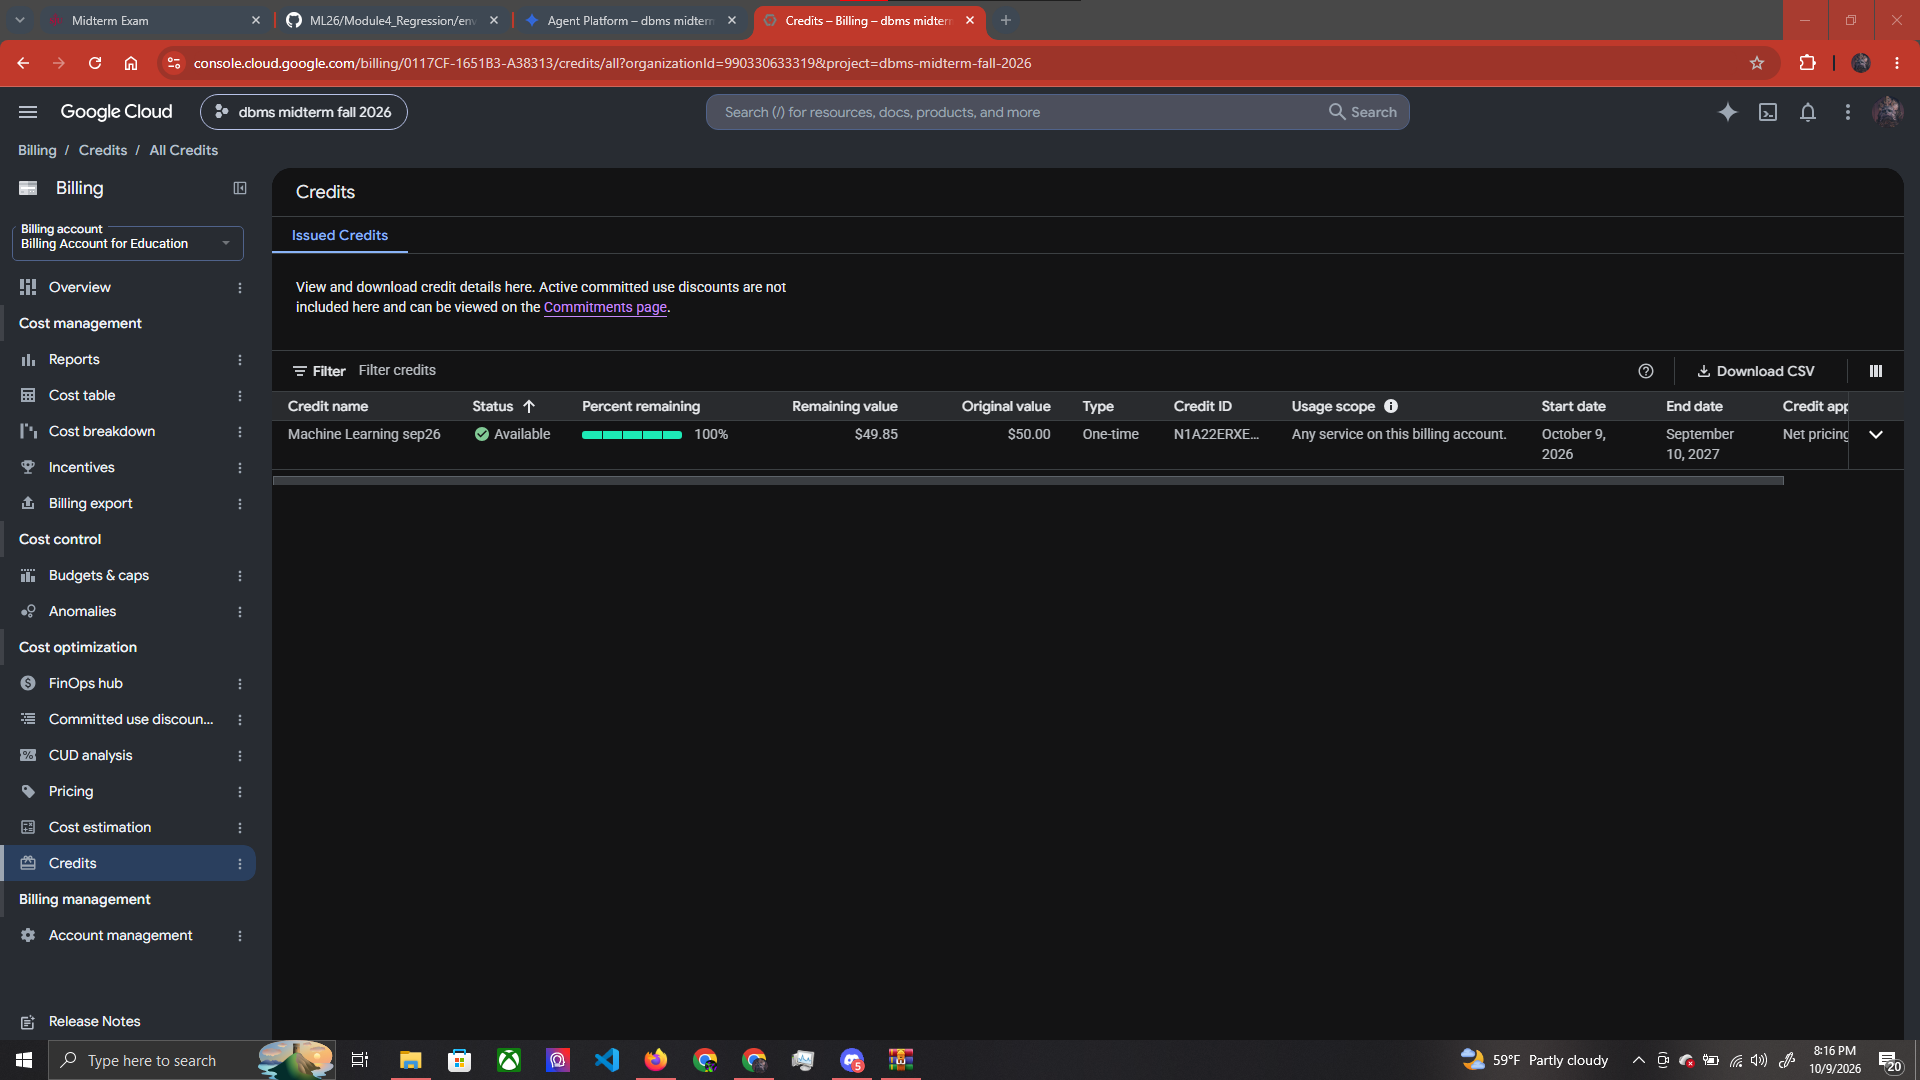